<a href="https://colab.research.google.com/github/ikuto1910-jp/california-housing-analysis/blob/main/california-housing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#step1

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 1. Web上のCSVファイルを直接読み込む
csv_url = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"
df_housing = pd.read_csv(csv_url)

# 2. 形状・先頭データ・欠損値の確認
print(f"=== データの形状 (行数, 列数) ===")
print(df_housing.shape)

print("\n=== 先頭5件 ===")
display(df_housing.head())

print("\n=== 列の情報と欠損値のチェック ===")
df_housing.info()



=== データの形状 (行数, 列数) ===
(20640, 10)

=== 先頭5件 ===


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY



=== 列の情報と欠損値のチェック ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [ ]:
import pandas as pd

# サンプルデータ作成
sample_df = pd.DataFrame({
    'エリア': ['千代田区', '新宿区', '渋谷区'],
    '専有面積(㎡)': [55.2, 70.1, 42.8],
    '成約価格(万円)': [8500, 6800, 7200],
})

print('--- ① print() で出力した場合（テキスト形式） ---')
print(sample_df)

print('\n--- ② display() で出力した場合（リッチなHTML表形式） ---')
display(sample_df)

--- ① print() で出力した場合（テキスト形式） ---
    エリア  専有面積(㎡)  成約価格(万円)
0  千代田区     55.2      8500
1   新宿区     70.1      6800
2   渋谷区     42.8      7200

--- ② display() で出力した場合（リッチなHTML表形式） ---


,エリア,専有面積(㎡),成約価格(万円)
0,千代田区,55.2,8500
1,新宿区,70.1,6800
2,渋谷区,42.8,7200


In [ ]:
df_housing.isnull().sum()

,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,207
population,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0


=== 欠損値のチェック ===


,欠損数,欠損割合(%)
total_bedrooms,207,1.0


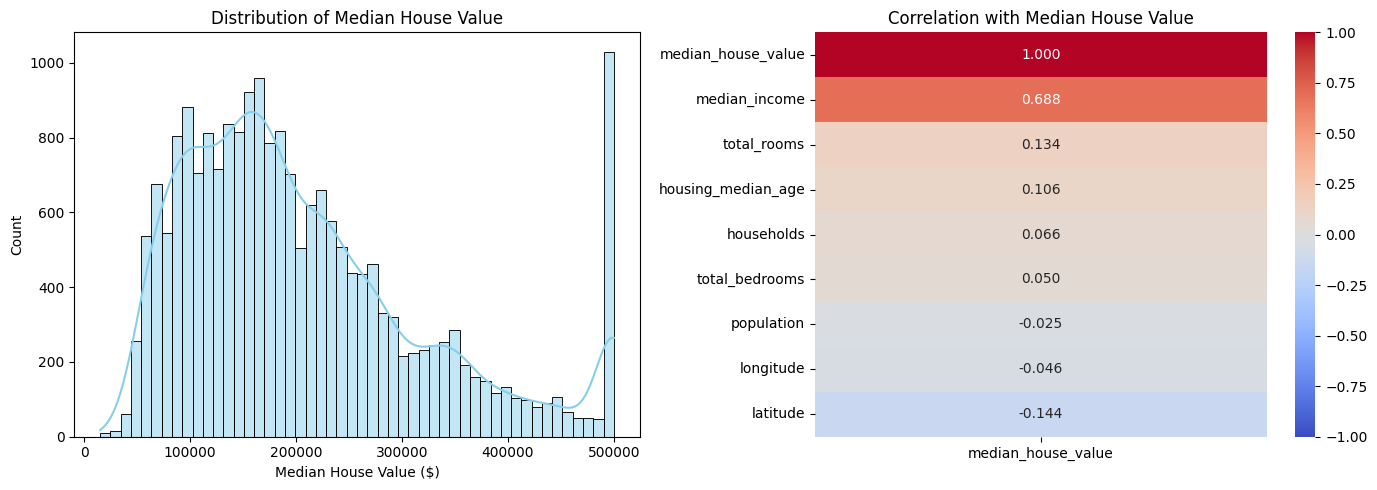

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# --------------------------------------------------
# 1. 欠損値の確認（個数と全体に対する割合）
# --------------------------------------------------
print("=== 欠損値のチェック ===")
null_counts = df_housing.isnull().sum()
null_percent = (null_counts / len(df_housing)) * 100

missing_df = pd.DataFrame(
    {"欠損数": null_counts, "欠損割合(%)": null_percent.round(2)}
)
# 欠損がある列だけを抽出して表示
display(missing_df[missing_df["欠損数"] > 0])

# --------------------------------------------------
# 2. 可視化：価格の分布 ＆ 特徴量の相関関係
# --------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ① 目的変数（住宅価格の中央値）のヒストグラム
sns.histplot(
    df_housing["median_house_value"],
    bins=50,
    kde=True,
    ax=axes[0],
    color="skyblue",
)
axes[0].set_title("Distribution of Median House Value")
axes[0].set_xlabel("Median House Value ($)")
axes[0].set_ylabel("Count")

# ② 目的変数と各数値特徴量の相関係数（ランキング）
numeric_cols = df_housing.select_dtypes(include=[np.number]).columns
corr_matrix = df_housing[numeric_cols].corr()

# 価格に対する相関の強い順に並べてヒートマップ描画
price_corr = corr_matrix[["median_house_value"]].sort_values(
    by="median_house_value", ascending=False
)

sns.heatmap(
    price_corr,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    ax=axes[1],
)
axes[1].set_title("Correlation with Median House Value")

plt.tight_layout()
plt.show()

In [ ]:
df_housing.isnull().sum()[df_housing.isnull().sum() > 0]

,0
total_bedrooms,207


In [ ]:
# --------------------------------------------------
# 1. 欠損値の補完（中央値による補完）
# --------------------------------------------------
# 元データを保護するためコピーを作成
df_clean = df_housing.copy()

# total_bedrooms の中央値（median）を計算
bedroom_median = df_clean["total_bedrooms"].median()
print(f"total_bedrooms の中央値: {bedroom_median} 部屋")

# 欠損値を中央値で穴埋め（補完）
df_clean["total_bedrooms"] = df_clean["total_bedrooms"].fillna(bedroom_median)

# --------------------------------------------------
# 2. カテゴリ変数（ocean_proximity）のダミー変数化
# --------------------------------------------------
print("\n=== ocean_proximity の内訳 ===")
print(df_clean["ocean_proximity"].value_counts())

# drop_first=True で多重共線性を防ぎつつ 0 / 1 に変換
df_encoded = pd.get_dummies(
    df_clean, columns=["ocean_proximity"], drop_first=True, dtype=int
)

# --------------------------------------------------
# 3. 特徴量 X（説明変数） と 正解ラベル y（目的変数）の分離
# --------------------------------------------------
X = df_encoded.drop(columns=["median_house_value"])
y = df_encoded["median_house_value"]

# --------------------------------------------------
# 4. 前処理後のデータ確認
# --------------------------------------------------
print(f"\n=== 前処理後の特徴量数: {X.shape[1]} 列 ===")
print("特徴量一覧:", list(X.columns))
print(f"X の欠損値の総数: {X.isnull().sum().sum()} 個（0個なら成功）")
display(X.head())

total_bedrooms の中央値: 435.0 部屋

=== ocean_proximity の内訳 ===
ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

=== 前処理後の特徴量数: 12 列 ===
特徴量一覧: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'ocean_proximity_INLAND', 'ocean_proximity_ISLAND', 'ocean_proximity_NEAR BAY', 'ocean_proximity_NEAR OCEAN']
X の欠損値の総数: 0 個（0個なら成功）


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,0,0,1,0
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,0,0,1,0
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,0,0,1,0
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,0,0,1,0
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,0,0,1,0


In [ ]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler

# --------------------------------------------------
# 1. 5分割交差検証の設定
# --------------------------------------------------
kf = KFold(n_splits=5, shuffle=True, random_state=42)

mae_list = []
oof_predictions = np.zeros(len(df_clean))  # 全20,640件分の予測値を記録する箱

fold = 1
for train_idx, test_idx in kf.split(X):
  # 学習用データとテスト用データに分割
  X_train_cv, X_test_cv = X.iloc[train_idx], X.iloc[test_idx]
  y_train_cv, y_test_cv = y.iloc[train_idx], y.iloc[test_idx]

  # 【重要】データリーク防止：Foldごとに標準化器を新規作成
  scaler = StandardScaler()
  X_train_scaled = scaler.fit_transform(X_train_cv)
  X_test_scaled = scaler.transform(X_test_cv)

  # 線形回帰モデルの学習と予測
  model = LinearRegression()
  model.fit(X_train_scaled, y_train_cv)
  preds = model.predict(X_test_scaled)

  # 予測値を保存 & このFoldの誤差を記録
  oof_predictions[test_idx] = preds
  fold_mae = mean_absolute_error(y_test_cv, preds)
  mae_list.append(fold_mae)

  print(f"Fold {fold}: MAE = ${fold_mae:,.2f}")
  fold += 1

# --------------------------------------------------
# 2. 全体での汎化性能評価
# --------------------------------------------------
final_mae = np.mean(mae_list)
final_r2 = r2_score(y, oof_predictions)

print("\n=== 線形回帰ベースラインモデルの評価結果 ===")
print(f"平均 MAE : ${final_mae:,.2f}")
print(f"全体 R2  : {final_r2:.3f}")

# --------------------------------------------------
# 3. 全データでの標準化係数（影響力ランキング）の確認
# --------------------------------------------------
scaler_all = StandardScaler()
X_scaled_all = scaler_all.fit_transform(X)

final_model = LinearRegression()
final_model.fit(X_scaled_all, y)

coef_df = pd.DataFrame({
    "特徴量": X.columns,
    "標準化係数($)": np.round(final_model.coef_, 2),
}).sort_values(by="標準化係数($)", key=abs, ascending=False)

print("\n=== 各特徴量の影響力（標準化係数：絶対値順） ===")
display(coef_df)
print(f"基準価格（切片）: ${final_model.intercept_:,.2f}")

Fold 1: MAE = $50,670.74
Fold 2: MAE = $50,586.33
Fold 3: MAE = $49,158.36
Fold 4: MAE = $48,107.82
Fold 5: MAE = $51,093.04

=== 線形回帰ベースラインモデルの評価結果 ===
平均 MAE : $49,923.26
全体 R2  : 0.643

=== 各特徴量の影響力（標準化係数：絶対値順） ===


,特徴量,標準化係数($)
7,median_income,73636.16
1,latitude,-53767.62
0,longitude,-52952.95
5,population,-44490.48
4,total_bedrooms,29920.77
6,households,29746.22
8,ocean_proximity_INLAND,-18509.75
2,housing_median_age,13312.88
3,total_rooms,-10320.06
9,ocean_proximity_ISLAND,2428.76


基準価格（切片）: $206,855.82


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler

# --------------------------------------------------
# 1. 新特徴量の作成（特徴量エンジニアリング）
# --------------------------------------------------
df_fe = df_clean.copy()

df_fe["rooms_per_household"] = df_fe["total_rooms"] / df_fe["households"]
df_fe["bedrooms_per_room"] = df_fe["total_bedrooms"] / df_fe["total_rooms"]
df_fe["population_per_household"] = df_fe["population"] / df_fe["households"]

# カテゴリ変数のダミー化
cat_cols = df_fe.select_dtypes(include=["object"]).columns
print(f"カテゴリ変数: {list(cat_cols)}")

df_fe_encoded = pd.get_dummies(
    df_fe, columns=cat_cols, drop_first=True, dtype=int
)

# 説明変数 X と 目的変数 y
X_fe = df_fe_encoded.drop(columns=["median_house_value"])
y_fe = df_fe_encoded["median_house_value"]

print(
    f"=== 特徴量数: {X.shape[1]} 列 → {X_fe.shape[1]} 列（3つの新特徴量を追加） ==="
)
display(
    X_fe[
        [
            "rooms_per_household",
            "bedrooms_per_room",
            "population_per_household",
        ]
    ].head()
)

# --------------------------------------------------
# 2. 5分割交差検証（新モデルの実力測定）
# --------------------------------------------------
kf = KFold(n_splits=5, shuffle=True, random_state=42)

mae_list_fe = []
oof_preds_fe = np.zeros(len(df_fe))

fold = 1
for train_idx, test_idx in kf.split(X_fe):
  X_train_cv, X_test_cv = X_fe.iloc[train_idx], X_fe.iloc[test_idx]
  y_train_cv, y_test_cv = y_fe.iloc[train_idx], y_fe.iloc[test_idx]

  scaler = StandardScaler()
  X_train_scaled = scaler.fit_transform(X_train_cv)
  X_test_scaled = scaler.transform(X_test_cv)

  model = LinearRegression()
  model.fit(X_train_scaled, y_train_cv)
  preds = model.predict(X_test_scaled)

  oof_preds_fe[test_idx] = preds
  mae_list_fe.append(mean_absolute_error(y_test_cv, preds))
  fold += 1

final_mae_fe = np.mean(mae_list_fe)
final_r2_fe = r2_score(y_fe, oof_preds_fe)

# --------------------------------------------------
# 3. ベースライン（前回の結果）との精度比較
# --------------------------------------------------
print("\n" + "=" * 50)
print("【モデル性能の比較（ベースライン vs 特徴量追加後）】")
print(
    f"平均 MAE : ${final_mae:,.2f}  →  ${final_mae_fe:,.2f} （改善幅: -${final_mae - final_mae_fe:,.2f}）"
)
print(
    f"全体 R2  : {final_r2:.3f}       →  {final_r2_fe:.3f}      （改善幅: +{final_r2_fe - final_r2:.3f}）"
)
print("=" * 50)

# --------------------------------------------------
# 4. 全データでの新・標準化係数ランキング
# --------------------------------------------------
scaler_all_fe = StandardScaler()
X_scaled_all_fe = scaler_all_fe.fit_transform(X_fe)

final_model_fe = LinearRegression()
final_model_fe.fit(X_scaled_all_fe, y_fe)

coef_df_fe = pd.DataFrame({
    "特徴量": X_fe.columns,
    "標準化係数($)": np.round(final_model_fe.coef_, 2),
}).sort_values(by="標準化係数($)", key=abs, ascending=True)  # グラフ描画用に絶対値昇順（下から上に向けて描画されるため）

print("\n=== 新モデルの標準化係数（影響力ランキング） ===")
display(coef_df_fe.iloc[::-1]) # 表は降順で見せる



カテゴリ変数: ['ocean_proximity']
=== 特徴量数: 12 列 → 15 列（3つの新特徴量を追加） ===


,rooms_per_household,bedrooms_per_room,population_per_household
0,6.984127,0.146591,2.555556
1,6.238137,0.155797,2.109842
2,8.288136,0.129516,2.802260
3,5.817352,0.184458,2.547945
4,6.281853,0.172096,2.181467



【モデル性能の比較（ベースライン vs 特徴量追加後）】
平均 MAE : $49,923.26  →  $49,574.43 （改善幅: -$348.83）
全体 R2  : 0.643       →  0.641      （改善幅: +-0.002）

=== 新モデルの標準化係数（影響力ランキング） ===


,特徴量,標準化係数($)
7,median_income,74791.32
1,latitude,-56255.15
0,longitude,-55320.72
5,population,-46331.97
6,households,45752.37
11,ocean_proximity_INLAND,-17345.58
2,housing_median_age,13364.74
9,bedrooms_per_room,9613.22
4,total_bedrooms,7465.25
8,rooms_per_household,6372.10


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge, Lasso  # ★ Ridge と Lasso を追加
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler

# --------------------------------------------------
# 2. 5分割交差検証（3つのモデルを同時に実力測定）
# --------------------------------------------------
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# それぞれのモデル用の評価記録箱を用意（前回の書き方と同じ）
oof_preds_lr = np.zeros(len(df_fe))
oof_preds_ridge = np.zeros(len(df_fe))
oof_preds_lasso = np.zeros(len(df_fe))

mae_list_lr = []
mae_list_ridge = []
mae_list_lasso = []

fold = 1
for train_idx, test_idx in kf.split(X_fe):
    # データの分割
    X_train_cv, X_test_cv = X_fe.iloc[train_idx], X_fe.iloc[test_idx]
    y_train_cv, y_test_cv = y_fe.iloc[train_idx], y_fe.iloc[test_idx]

    # Fold内標準化（データリーク防止）
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_cv)
    X_test_scaled = scaler.transform(X_test_cv)

    # --- モデル1: 通常の線形回帰（ベースライン） ---
    model_lr = LinearRegression()
    model_lr.fit(X_train_scaled, y_train_cv)
    preds_lr = model_lr.predict(X_test_scaled)
    oof_preds_lr[test_idx] = preds_lr
    mae_list_lr.append(mean_absolute_error(y_test_cv, preds_lr))

    # --- モデル2: Ridge回帰（係数を縮小して安定化） ---
    model_ridge = Ridge(alpha=100.0)
    model_ridge.fit(X_train_scaled, y_train_cv)
    preds_ridge = model_ridge.predict(X_test_scaled)
    oof_preds_ridge[test_idx] = preds_ridge
    mae_list_ridge.append(mean_absolute_error(y_test_cv, preds_ridge))

    # --- モデル3: Lasso回帰（不要な係数を0にして特徴量選択） ---
    model_lasso = Lasso(alpha=100.0, random_state=42)
    model_lasso.fit(X_train_scaled, y_train_cv)
    preds_lasso = model_lasso.predict(X_test_scaled)
    oof_preds_lasso[test_idx] = preds_lasso
    mae_list_lasso.append(mean_absolute_error(y_test_cv, preds_lasso))

    fold += 1

# 各モデルの最終成績を計算
final_mae_lr = np.mean(mae_list_lr)
final_r2_lr = r2_score(y_fe, oof_preds_lr)

final_mae_ridge = np.mean(mae_list_ridge)
final_r2_ridge = r2_score(y_fe, oof_preds_ridge)

final_mae_lasso = np.mean(mae_list_lasso)
final_r2_lasso = r2_score(y_fe, oof_preds_lasso)

# --------------------------------------------------
# 3. モデル精度の比較表
# --------------------------------------------------
print("\n" + "=" * 55)
print("【モデル性能の比較（5-Fold CV）】")
performance_df = pd.DataFrame({
    "モデル": ["線形回帰（通常）", "Ridge回帰 (alpha=100)", "Lasso回帰 (alpha=100)"],
    "平均 MAE ($)": [f"${final_mae_lr:,.2f}", f"${final_mae_ridge:,.2f}", f"${final_mae_lasso:,.2f}"],
    "全体 R²": [f"{final_r2_lr:.4f}", f"{final_r2_ridge:.4f}", f"{final_r2_lasso:.4f}"]
})
display(performance_df)
print("=" * 55)

# --------------------------------------------------
# 4. 全データでの標準化係数の比較（3モデル並列）
# --------------------------------------------------
# 全データで標準化
scaler_all_fe = StandardScaler()
X_scaled_all_fe = scaler_all_fe.fit_transform(X_fe)

# 全データで学習
final_lr = LinearRegression().fit(X_scaled_all_fe, y_fe)
final_ridge = Ridge(alpha=100.0).fit(X_scaled_all_fe, y_fe)
final_lasso = Lasso(alpha=100.0, random_state=42).fit(X_scaled_all_fe, y_fe)

# 3つのモデルの係数を1つの表にまとめる
coef_comparison_df = pd.DataFrame({
    "特徴量": X_fe.columns,
    "線形回帰 ($)": np.round(final_lr.coef_, 2),
    "Ridge ($)": np.round(final_ridge.coef_, 2),
    "Lasso ($)": np.round(final_lasso.coef_, 2)
})

# 線形回帰の係数の絶対値が大きい順に並べ替えて表示
coef_comparison_df["abs_lr"] = coef_comparison_df["線形回帰 ($)"].abs()
coef_comparison_df = coef_comparison_df.sort_values(by="abs_lr", ascending=False).drop(columns=["abs_lr"])

print("\n=== 各モデルの標準化係数（影響度）の比較 ===")
display(coef_comparison_df)



【モデル性能の比較（5-Fold CV）】


,モデル,平均 MAE ($),全体 R²
0,線形回帰（通常）,"$49,574.43",0.6414
1,Ridge回帰 (alpha=100),"$49,554.62",0.6416
2,Lasso回帰 (alpha=100),"$49,551.84",0.6419



=== 各モデルの標準化係数（影響度）の比較 ===


,特徴量,線形回帰 ($),Ridge ($),Lasso ($)
7,median_income,74791.32,74679.29,74617.51
1,latitude,-56255.15,-48096.70,-52990.05
0,longitude,-55320.72,-47666.70,-52138.59
5,population,-46331.97,-43666.92,-45346.65
6,households,45752.37,39583.22,43983.91
11,ocean_proximity_INLAND,-17345.58,-19574.12,-18179.40
2,housing_median_age,13364.74,13458.49,13298.24
9,bedrooms_per_room,9613.22,9200.57,9715.38
4,total_bedrooms,7465.25,10692.37,6446.57
8,rooms_per_household,6372.10,5571.90,5915.15


In [ ]:
coef_comparison_df.info()
coef_comparison_df.head()
coef_comparison_df.shape

<class 'pandas.core.frame.DataFrame'>
Index: 15 entries, 7 to 10
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   特徴量        15 non-null     object 
 1   線形回帰 ($)   15 non-null     float64
 2   Ridge ($)  15 non-null     float64
 3   Lasso ($)  15 non-null     float64
dtypes: float64(3), object(1)
memory usage: 600.0+ bytes


(15, 4)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 56.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for japanize_matplotlib: filename=japanize_matplotlib-1.1.3-py3-none-any.whl size=4120306 sha256=402881178da6c7de2d67e52651898bc4f947c23c125488687d41ce3389a0c5a3
  Stored in directory: /root/.cache/pip/wheels/56/8b/41/7c8a47025c6eef46f0b7488f2510fff13e48f1e7d5bf26e21b
Successfully built japanize_matplotlib


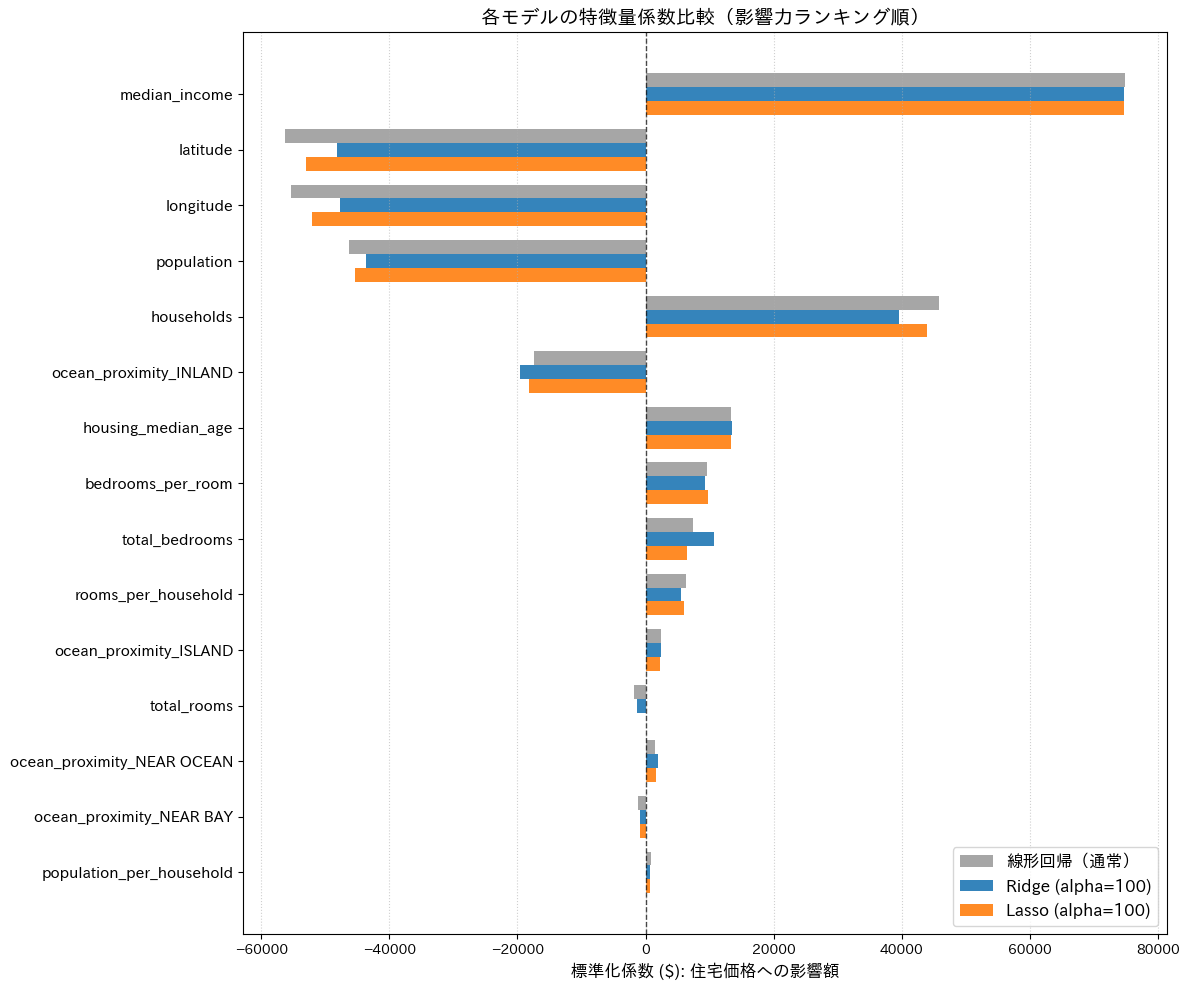

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
!pip install japanize_matplotlib
import japanize_matplotlib


# --------------------------------------------------
# 係数比較の横棒グラフ（見やすさ最優先のシンプル版）
# --------------------------------------------------
# 表示する特徴量のリスト（下から上に向かって描画されるため、逆順にして上が1位になるように配置）
features = coef_comparison_df["特徴量"].values[::-1]
lr_vals = coef_comparison_df["線形回帰 ($)"].values[::-1]
ridge_vals = coef_comparison_df["Ridge ($)"].values[::-1]
lasso_vals = coef_comparison_df["Lasso ($)"].values[::-1]

# グラフの縦の位置を設定
y_indices = np.arange(len(features))
bar_height = 0.25  # 棒の太さ

plt.figure(figsize=(12, 10))

# 3本の棒を少しずつ上下にずらして描画
plt.barh(y_indices + bar_height, lr_vals, height=bar_height, label="線形回帰（通常）", color="gray", alpha=0.7)
plt.barh(y_indices, ridge_vals, height=bar_height, label="Ridge (alpha=100)", color="tab:blue", alpha=0.9)
plt.barh(y_indices - bar_height, lasso_vals, height=bar_height, label="Lasso (alpha=100)", color="tab:orange", alpha=0.9)

# 基準線（0のライン）
plt.axvline(0, color="black", linestyle="--", linewidth=1, alpha=0.7)

# 軸とラベルの設定
plt.yticks(y_indices, features, fontsize=11)
plt.xlabel("標準化係数 ($): 住宅価格への影響額", fontsize=12)
plt.title("各モデルの特徴量係数比較（影響力ランキング順）", fontsize=14, weight="bold")
plt.legend(fontsize=12, loc="lower right")
plt.grid(axis="x", linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

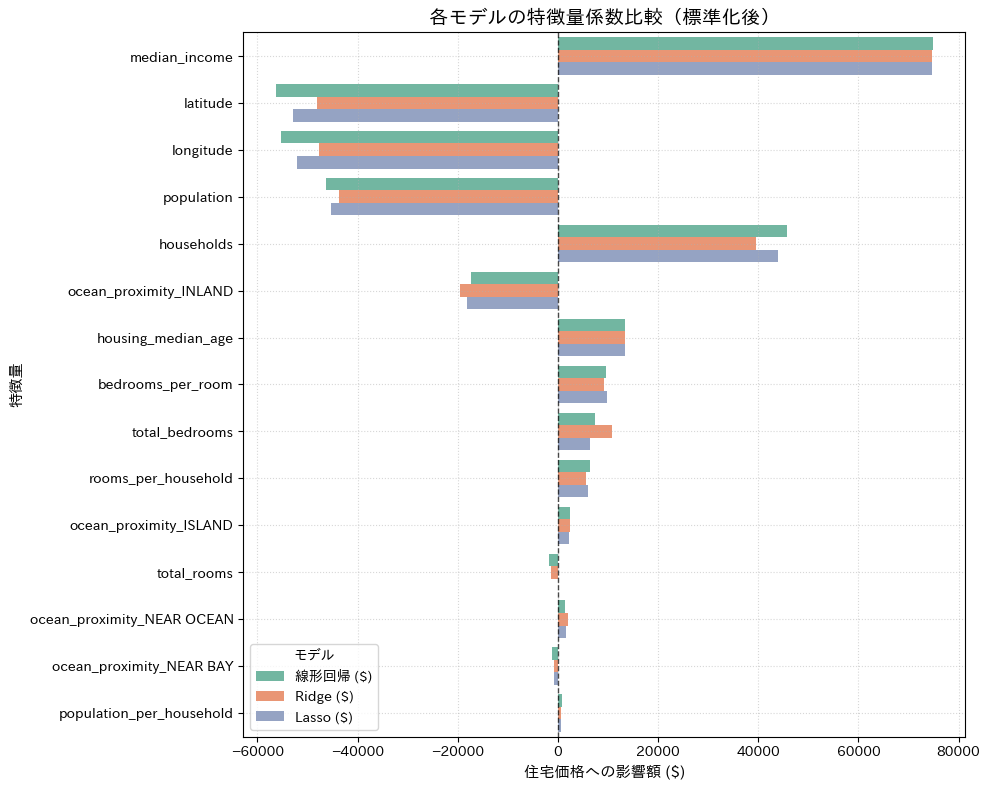

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# --------------------------------------------------
# ステップ1: 表を Seaborn が読みやすい形に整える（縦持ち変換）
# --------------------------------------------------
# 表の列（線形回帰, Ridge, Lasso）を「モデル」という1つの列にまとめる
df_plot = coef_comparison_df.melt(
    id_vars="特徴量",
    var_name="モデル",
    value_name="係数 ($)"
)

# --------------------------------------------------
# ステップ2: Seaborn で描画（これまでの知識だけで書けます！）
# --------------------------------------------------
plt.figure(figsize=(10, 8))

# hue='モデル' を指定するだけで、自動で3本並べて色分けしてくれる！
sns.barplot(
    data=df_plot,
    x="係数 ($)",
    y="特徴量",
    hue="モデル",
    palette="Set2"
)

# 基準線（0の境界線）を引く
plt.axvline(0, color="black", linestyle="--", linewidth=1, alpha=0.7)

# 仕上げ（タイトルと軸ラベル）
plt.title("各モデルの特徴量係数比較（標準化後）", fontsize=14, weight="bold")
plt.xlabel("住宅価格への影響額 ($)", fontsize=11)
plt.ylabel("特徴量", fontsize=11)
plt.grid(True, linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

# 1. テスト用の横長データを作成
sample_df = pd.DataFrame({
    "名前": ["田中", "鈴木"],
    "国語": [80, 95],
    "数学": [70, 85]
})
print("=== 変換前（横長） ===")
print(sample_df)

# 2. melt で縦長に変換
melted_df = sample_df.melt(
    id_vars="名前",       # 固定する列
    var_name="科目",      # 列名を集める新しい列の名前
    value_name="点数"     # 数値を集める新しい列の名前
)
print("\n=== 変換後（縦長） ===")
print(melted_df)

=== 変換前（横長） ===
   名前  国語  数学
0  田中  80  70
1  鈴木  95  85

=== 変換後（縦長） ===
   名前  科目  点数
0  田中  国語  80
1  鈴木  国語  95
2  田中  数学  70
3  鈴木  数学  85


In [ ]:
# --------------------------------------------------
# Lasso (alpha=100) で係数が 0 になった特徴量を自動抽出
# --------------------------------------------------
zero_features = coef_comparison_df[coef_comparison_df["Lasso ($)"] == 0]["特徴量"].tolist()
survived_df = coef_comparison_df[coef_comparison_df["Lasso ($)"] != 0][["特徴量", "Lasso ($)", "Ridge ($)", "線形回帰 ($)"]]

print(f"【Lassoで切り捨てられた特徴量（計 {len(zero_features)} 個）】")
print(zero_features)

print("\n【Lassoで生き残った特徴量（影響力順）】")
display(survived_df)

【Lassoで切り捨てられた特徴量（計 1 個）】
['total_rooms']

【Lassoで生き残った特徴量（影響力順）】


,特徴量,Lasso ($),Ridge ($),線形回帰 ($)
7,median_income,74617.51,74679.29,74791.32
1,latitude,-52990.05,-48096.70,-56255.15
0,longitude,-52138.59,-47666.70,-55320.72
5,population,-45346.65,-43666.92,-46331.97
6,households,43983.91,39583.22,45752.37
11,ocean_proximity_INLAND,-18179.40,-19574.12,-17345.58
2,housing_median_age,13298.24,13458.49,13364.74
9,bedrooms_per_room,9715.38,9200.57,9613.22
4,total_bedrooms,6446.57,10692.37,7465.25
8,rooms_per_household,5915.15,5571.90,6372.10


Google Colaboratoryでそのままコピペして実行できる、Step 1（データ操作と可視化）の最短ハンズオンです。
架空の「ECサイトの顧客購買データ」をコード内で自動生成するため、外部ファイルのダウンロードや環境設定は一切不要です。Google Colabのコードセルに順番に貼り付けて実行してください。
演習1：データの作成と中身の確認（1分）
最初のセルに以下を貼り付けて実行（Ctrl + Enter または再生ボタン）します。
Python

import pandas as pdimport numpy as np# 演習用の架空データ（10人分の顧客データ）を作成
data = {
    'ユーザーID': [101, 102, 103, 104, 105, 106, 107, 108, 109, 110],
    '年代': ['20代', '30代', '20代', '40代', '30代', '20代', '40代', '30代', '20代', '50代'],
    '性別': ['女性', '男性', '女性', '男性', '女性', '男性', '女性', '女性', '男性', '男性'],
    '購入金額': [12000, 3500, 8900, 24000, np.nan, 4500, 18000, 9200, 1500, 31000], # 1件欠損値(NaN)
    '会員ランク': ['ゴールド', 'ブロンズ', 'シルバー', 'プラチナ', 'シルバー', 'ブロンズ', 'ゴールド', 'シルバー', 'ブロンズ', 'プラチナ']
}# DataFrame（表形式データ）に変換
df = pd.DataFrame(data)# 先頭5行を表示
df.head()
- ポイント： pd.DataFrame() でPythonの辞書データを表形式に変換し、.head() でデータの先頭を確認します。
演習2：データの状態チェック（欠損値・基本統計量）（1分）
次のセルを作成し、実務で最初に行う「データの健康診断」を実行します。
Python

# 1. データの行数・列数・データ型・欠損値の有無を確認
print("--- 基本情報 ---")
df.info()# 2. 数値列（購入金額）の要約統計量（平均、最小、最大、中央値など）
print("\n--- 統計量まとめ ---")
print(df.describe())# 3. 欠損値（空欄）が何個あるか確認
print("\n--- 各列の欠損値の数 ---")
print(df.isnull().sum())
- ポイント： 購入金額 に欠損（NaN）が1つあることが確認できます。実務の生データには必ず欠損が存在します。
演習3：データの抽出とグループ集計（2分）
実務で最も頻繁に使う「絞り込み」と「グループ別の集計」です。
Python

# 1. 条件抽出：購入金額が1万円以上の人だけを取り出す
high_spenders = df[df['購入金額'] >= 10000]
print("--- 1万円以上の顧客 ---")
print(high_spenders[['ユーザーID', '年代', '購入金額']])# 2. グループ集計：年代ごとの平均購入金額を算出
age_summary = df.groupby('年代')['購入金額'].mean().reset_index()
print("\n--- 年代別の平均購入金額 ---")
print(age_summary)# 3. クロス集計：年代 × 会員ランク の人数分布
cross_tab = pd.crosstab(df['年代'], df['会員ランク'])
print("\n--- 年代 × 会員ランクのクロス表 ---")
print(cross_tab)
- ポイント： df[条件式] で抽出、df.groupby('まとめる列')['計算する列'].mean() で集計します。
演習4：グラフによるデータの可視化（2分）
数字の羅列をグラフに変換します。
Python

import matplotlib.pyplot as plt# 日本語表示のためのフォント設定（文字化け防止）
!pip install japanize-matplotlibimport japanize_matplotlib# グラフの枠組みを作成
fig, axes = plt.subplots(1, 2, figsize=(12, 4))# 1. 年代別の平均購入金額（棒グラフ）
axes[0].bar(age_summary['年代'], age_summary['購入金額'], color='skyblue')
axes[0].set_title('年代別 平均購入金額')
axes[0].set_xlabel('年代')
axes[0].set_ylabel('円')# 2. 会員ランクごとの人数分布（カウント）
rank_counts = df['会員ランク'].value_counts()
axes[1].bar(rank_counts.index, rank_counts.values, color='lightgreen')
axes[1].set_title('会員ランク別 ユーザー数')
axes[1].set_xlabel('ランク')
axes[1].set_ylabel('人数')

plt.tight_layout()
plt.show()
自力で解いてみるミニ課題
理解の確認として、以下の2つの処理を書けるか試してみてください。
1. 課題A： 性別が「女性」の顧客だけを抽出して表示してください。
2. 課題B： 「会員ランク」ごとの「購入金額」の合計（.sum()）を集計してください。
書けたコードや、実行してエラーが出た箇所があればそのまま返信してください。

In [ ]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler

# --------------------------------------------------
# 1. 探索する alpha（正則化の強さ）の候補リスト
# --------------------------------------------------
alphas_list = [0.1, 1.0, 10.0, 100.0, 1000.0, 10000.0]

# --------------------------------------------------
# 2. 5分割交差検証（最適な alpha を探索しながら評価）
# --------------------------------------------------
kf = KFold(n_splits=5, shuffle=True, random_state=42)

oof_preds_lr = np.zeros(len(df_fe))
oof_preds_ridge = np.zeros(len(df_fe))
oof_preds_lasso = np.zeros(len(df_fe))

mae_list_lr = []
mae_list_ridge = []
mae_list_lasso = []

best_alphas_ridge = []
best_alphas_lasso = []

for train_idx, test_idx in kf.split(X_fe):
    X_train_cv, X_test_cv = X_fe.iloc[train_idx], X_fe.iloc[test_idx]
    y_train_cv, y_test_cv = y_fe.iloc[train_idx], y_fe.iloc[test_idx]

    # Fold内標準化（データリーク防止）
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_cv)
    X_test_scaled = scaler.transform(X_test_cv)

    # ① 線形回帰（基準）
    model_lr = LinearRegression()
    model_lr.fit(X_train_scaled, y_train_cv)
    preds_lr = model_lr.predict(X_test_scaled)
    oof_preds_lr[test_idx] = preds_lr
    mae_list_lr.append(mean_absolute_error(y_test_cv, preds_lr))

    # ② RidgeCV（最適な alpha を自動選択）
    model_ridge = RidgeCV(alphas=alphas_list)
    model_ridge.fit(X_train_scaled, y_train_cv)
    preds_ridge = model_ridge.predict(X_test_scaled)
    oof_preds_ridge[test_idx] = preds_ridge
    mae_list_ridge.append(mean_absolute_error(y_test_cv, preds_ridge))
    best_alphas_ridge.append(model_ridge.alpha_)

    # ③ LassoCV（最適な alpha を自動選択）
    model_lasso = LassoCV(alphas=alphas_list, cv=3, random_state=42, max_iter=3000)
    model_lasso.fit(X_train_scaled, y_train_cv)
    preds_lasso = model_lasso.predict(X_test_scaled)
    oof_preds_lasso[test_idx] = preds_lasso
    mae_list_lasso.append(mean_absolute_error(y_test_cv, preds_lasso))
    best_alphas_lasso.append(model_lasso.alpha_)

# 最終スコア集計
final_mae_lr = np.mean(mae_list_lr)
final_r2_lr = r2_score(y_fe, oof_preds_lr)

final_mae_ridge = np.mean(mae_list_ridge)
final_r2_ridge = r2_score(y_fe, oof_preds_ridge)

final_mae_lasso = np.mean(mae_list_lasso)
final_r2_lasso = r2_score(y_fe, oof_preds_lasso)

# --------------------------------------------------
# 3. 性能比較表の表示
# --------------------------------------------------
print("\n" + "=" * 60)
print("【モデル性能の比較（自動最適化後）】")
performance_df = pd.DataFrame({
    "モデル": ["線形回帰", "RidgeCV (最適化)", "LassoCV (最適化)"],
    "選ばれた平均 alpha": ["-", f"{np.mean(best_alphas_ridge):.1f}", f"{np.mean(best_alphas_lasso):.1f}"],
    "平均 MAE ($)": [f"${final_mae_lr:,.2f}", f"${final_mae_ridge:,.2f}", f"${final_mae_lasso:,.2f}"],
    "全体 R²": [f"{final_r2_lr:.4f}", f"{final_r2_ridge:.4f}", f"{final_r2_lasso:.4f}"]
})
display(performance_df)
print("=" * 60)


【モデル性能の比較（自動最適化後）】


,モデル,選ばれた平均 alpha,平均 MAE ($),全体 R²
0,線形回帰,-,"$49,574.43",0.6414
1,RidgeCV (最適化),10.0,"$49,568.03",0.6415
2,LassoCV (最適化),64.0,"$49,560.11",0.6417


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(



【モデル性能の比較（線形モデル vs 非線形モデル）】


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


,モデル,選ばれた平均 alpha,平均 MAE ($),全体 R²
0,線形回帰,-,"$49,574.43",0.6414
1,RidgeCV (最適化),10.0,"$49,568.03",0.6415
2,LassoCV (最適化),64.0,"$49,560.11",0.6417
3,LightGBM,-,"$29,401.72",0.8501


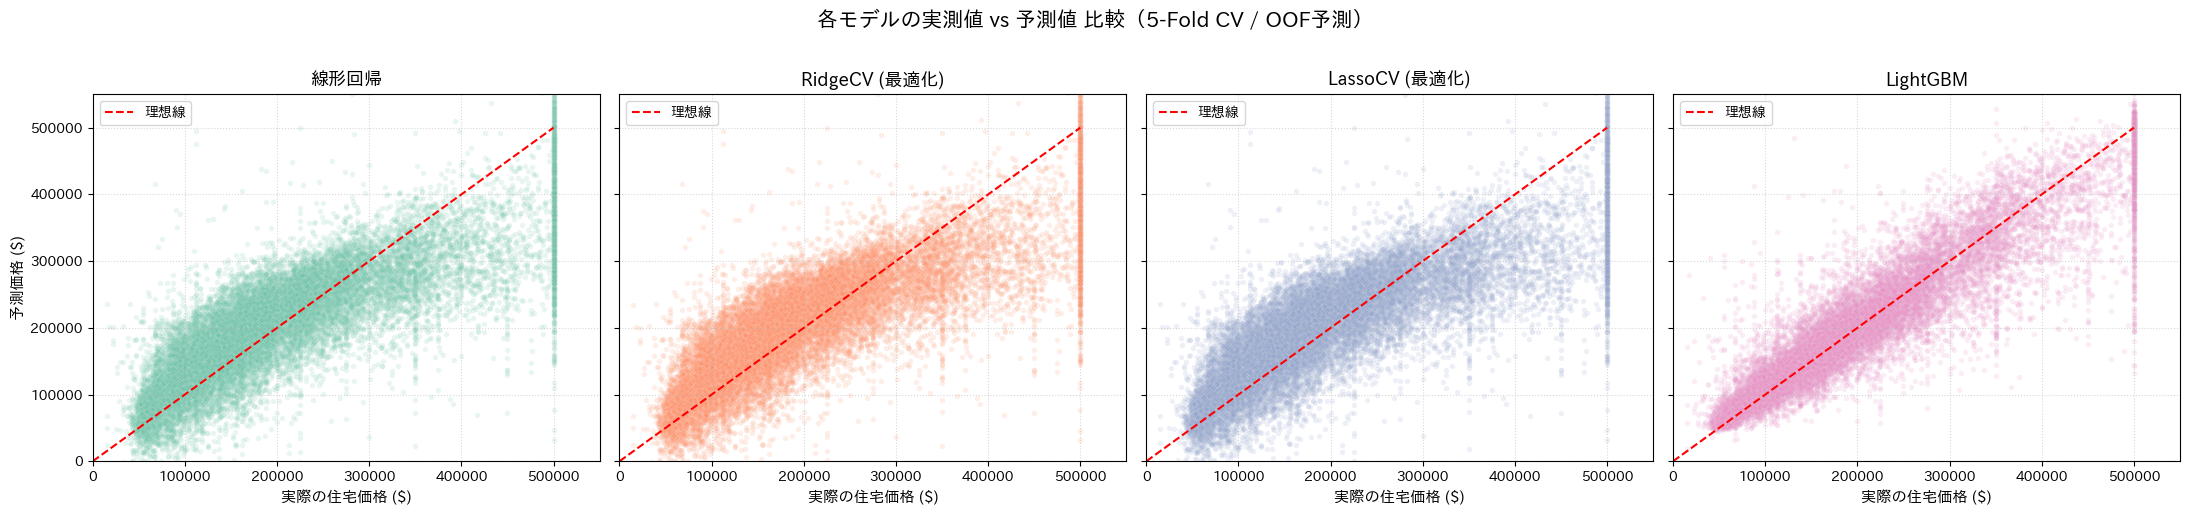

In [ ]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
import seaborn as sns
import matplotlib.pyplot as plt
from lightgbm import LGBMRegressor

# ==================================================
# 1. 共通評価関数
# ==================================================
def evaluate_cv(model, X, y, n_splits=5, random_state=42):
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    oof_preds = np.zeros(len(X))
    mae_list = []
    best_alphas = []

    for train_idx, test_idx in kf.split(X):
        X_train_cv, X_test_cv = X.iloc[train_idx], X.iloc[test_idx]
        y_train_cv, y_test_cv = y.iloc[train_idx], y.iloc[test_idx]

        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train_cv)
        X_test_scaled = scaler.transform(X_test_cv)

        model.fit(X_train_scaled, y_train_cv)
        preds = model.predict(X_test_scaled)

        oof_preds[test_idx] = preds
        mae_list.append(mean_absolute_error(y_test_cv, preds))

        if hasattr(model, "alpha_"):
            best_alphas.append(model.alpha_)

    final_mae = np.mean(mae_list)
    final_r2 = r2_score(y, oof_preds)
    avg_alpha = np.mean(best_alphas) if len(best_alphas) > 0 else None

    return {
        "mean_mae": final_mae,
        "overall_r2": final_r2,
        "avg_alpha": avg_alpha,
        "oof_preds": oof_preds
    }

# ==================================================
# 2. モデルの実行とプロット用データの蓄積
# ==================================================
alphas_list = [0.1, 1.0, 10.0, 100.0, 1000.0, 10000.0]

# 4つのモデルを定義
models = {
    "線形回帰": LinearRegression(),
    "RidgeCV (最適化)": RidgeCV(alphas=alphas_list),
    "LassoCV (最適化)": LassoCV(alphas=alphas_list, cv=3, random_state=42, max_iter=3000),
    "LightGBM": LGBMRegressor(random_state=42, n_estimators=200, verbosity=-1)
}

results_list = []
df_scatter_list = []

for model_name, model in models.items():
    res = evaluate_cv(model, X_fe, y_fe)

    results_list.append({
        "モデル": model_name,
        "選ばれた平均 alpha": f"{res['avg_alpha']:.1f}" if res['avg_alpha'] is not None else "-",
        "平均 MAE ($)": f"${res['mean_mae']:,.2f}",
        "全体 R²": f"{res['overall_r2']:.4f}"
    })

    df_temp = pd.DataFrame({
        "モデル": model_name,
        "実際の値": y_fe.values,
        "予測値": res["oof_preds"]
    })
    df_scatter_list.append(df_temp)

df_scatter_all = pd.concat(df_scatter_list, axis=0, ignore_index=True)

# 性能比較表の表示
performance_df = pd.DataFrame(results_list)
print("\n" + "=" * 60)
print("【モデル性能の比較（線形モデル vs 非線形モデル）】")
display(performance_df)
print("=" * 60)

# ==================================================
# 3. 散布図の横並び可視化 (1行 × 4列)
# ==================================================
# 辞書から自動でモデル名一覧を取り出す（修正ポイント！）
model_names = list(models.keys())

fig, axes = plt.subplots(1, 4, figsize=(22, 5), sharey=True)
colors = sns.color_palette("Set2", n_colors=len(model_names))

for i, name in enumerate(model_names):
    df_sub = df_scatter_all[df_scatter_all["モデル"] == name]
    ax = axes[i]

    sns.scatterplot(
        data=df_sub,
        x="実際の値",
        y="予測値",
        color=colors[i],
        alpha=0.15,
        s=15,
        ax=ax
    )

    ax.plot([0, 500000], [0, 500000], color="red", linestyle="--", linewidth=1.5, label="理想線")

    ax.set_title(f"{name}", fontsize=13, weight="bold")
    ax.set_xlabel("実際の住宅価格 ($)", fontsize=11)
    if i == 0:
        ax.set_ylabel("予測価格 ($)", fontsize=11)

    ax.set_xlim(0, 550000)
    ax.set_ylim(0, 550000)
    ax.grid(True, linestyle=":", alpha=0.5)
    ax.legend(loc="upper left")

plt.suptitle("各モデルの実測値 vs 予測値 比較（5-Fold CV / OOF予測）", fontsize=15, weight="bold", y=1.02)
plt.tight_layout()
plt.show()

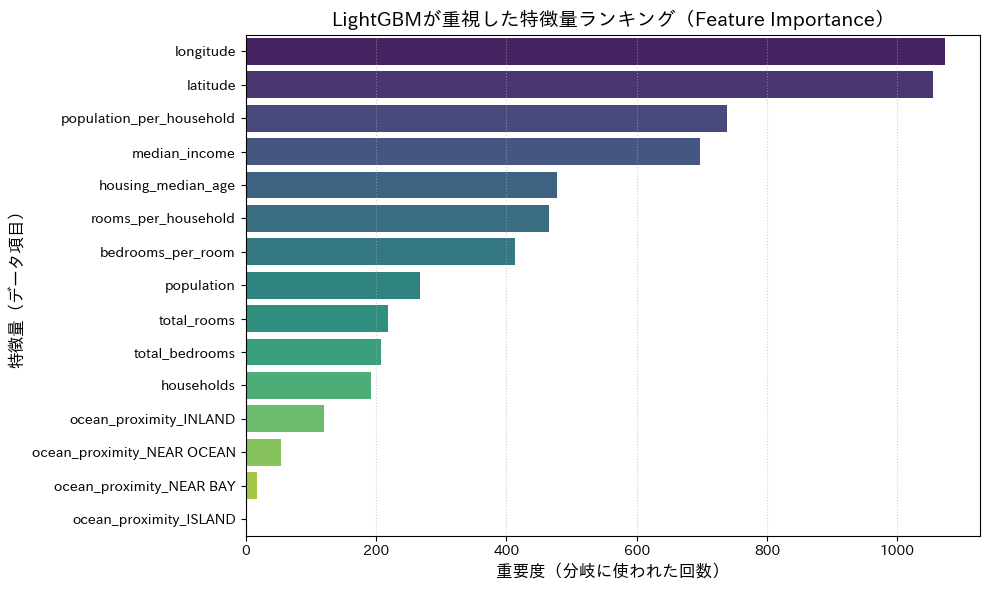

【LightGBM 変数重要度 トップ5】


,特徴量,重要度
0,longitude,1073
1,latitude,1055
2,population_per_household,739
3,median_income,697
4,housing_median_age,477


In [ ]:
# --------------------------------------------------
# LightGBMの「変数重要度（Feature Importance）」を可視化するコード
# --------------------------------------------------
# 辞書からLightGBMモデルを取り出す
lgbm_model = models["LightGBM"]

# 変数（特徴量）の名前リストを取得
feature_names = X_fe.columns

# モデルが学習した重要度スコアを取得
# ※ 今回は5-Fold CVの最後のFoldで学習したモデルの重要度を使用します
importances = lgbm_model.feature_importances_

# 見やすいようにデータフレームにまとめる
df_importance = pd.DataFrame({
    "特徴量": feature_names,
    "重要度": importances
})

# 重要度が高い順に並び替え
df_importance = df_importance.sort_values(by="重要度", ascending=False).reset_index(drop=True)

# 棒グラフで可視化
plt.figure(figsize=(10, 6))
sns.barplot(data=df_importance, x="重要度", y="特徴量", palette="viridis", hue='特徴量', legend=False)

plt.title("LightGBMが重視した特徴量ランキング（Feature Importance）", fontsize=14, weight="bold")
plt.xlabel("重要度（分岐に使われた回数）", fontsize=12)
plt.ylabel("特徴量（データ項目）", fontsize=12)
plt.grid(axis="x", linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

# 上位5つをテキストでも表示
print("【LightGBM 変数重要度 トップ5】")
display(df_importance.head(5))

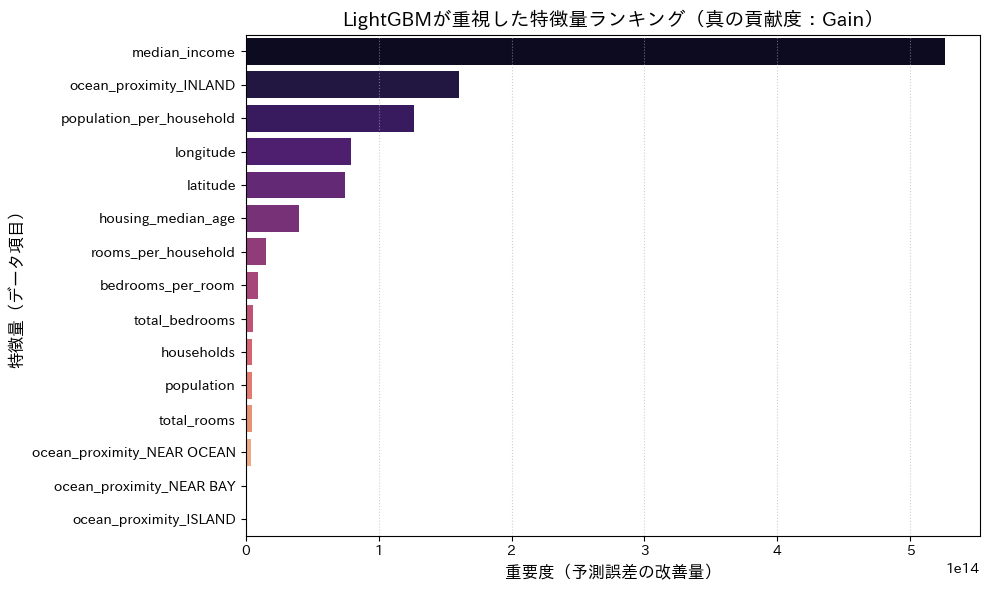

【LightGBM 変数重要度（Gain）トップ5】


,特徴量,重要度 (Gain)
0,median_income,5.261069e+14
1,ocean_proximity_INLAND,1.603045e+14
2,population_per_household,1.269327e+14
3,longitude,7.940517e+13
4,latitude,7.505720e+13


In [ ]:
# --------------------------------------------------
# 真の実力（Gain：誤差の改善量）による変数重要度の可視化
# --------------------------------------------------
# importance_type="gain" を指定して、真の貢献度を取得！
importances_gain = lgbm_model.booster_.feature_importance(importance_type="gain")

df_gain = pd.DataFrame({
    "特徴量": feature_names,
    "重要度 (Gain)": importances_gain
})

df_gain = df_gain.sort_values(by="重要度 (Gain)", ascending=False).reset_index(drop=True)

plt.figure(figsize=(10, 6))
# 警告が出ないように hue を追加した最新の書き方
sns.barplot(data=df_gain, x="重要度 (Gain)", y="特徴量", hue="特徴量", palette="magma", legend=False)

plt.title("LightGBMが重視した特徴量ランキング（真の貢献度：Gain）", fontsize=14, weight="bold")
plt.xlabel("重要度（予測誤差の改善量）", fontsize=12)
plt.ylabel("特徴量（データ項目）", fontsize=12)
plt.grid(axis="x", linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

print("【LightGBM 変数重要度（Gain）トップ5】")
display(df_gain.head(5))